<a href="https://colab.research.google.com/github/arunpr2313/24ADI006_24BAD012/blob/main/Experiment08/Experiment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT NO: 8 — Train a Simple Autoencoder for Dimensionality Reduction and Feature Learning
 Arun PR— 24BAD012



## Part A: Dataset Preparation and Preprocessing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Student:", "Arun PR  24BAD012")
print("TensorFlow version:", tf.__version__)

# Reproducibility
np.random.seed(31)
tf.random.set_seed(31)

# Load MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Explore dataset
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape :", x_test.shape)
print("Testing labels shape :", y_test.shape)
print("Pixel value range    :", x_train.min(), "-", x_train.max(), "| dtype:", x_train.dtype)

Student: Arun PR  24BAD012
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape : (10000, 28, 28)
Testing labels shape : (10000,)
Pixel value range    : 0 - 255 | dtype: uint8


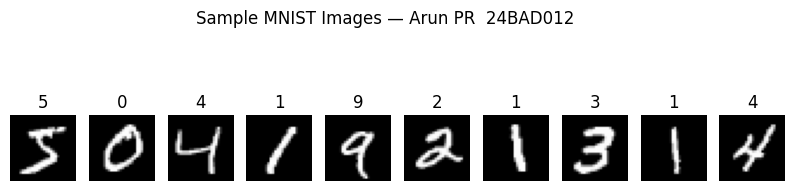

In [2]:
# Display sample images  |  Arun PR  24BAD012
plt.figure(figsize=(10, 2.5))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(str(y_train[i]))
    plt.axis("off")
plt.suptitle("Sample MNIST Images — Arun PR  24BAD012", y=1.05)
plt.show()

In [3]:
# Normalize to [0, 1] and flatten 28x28 -> 784  |  Arun PR  24BAD012
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

x_train_flat = x_train.reshape((len(x_train), 784))
x_test_flat  = x_test.reshape((len(x_test), 784))

print("Flattened training shape:", x_train_flat.shape)
print("Flattened testing shape :", x_test_flat.shape)
print("New pixel range:", x_train_flat.min(), "-", x_train_flat.max())

# The autoencoder uses the input as its own target:
#   input  = x_train_flat,  target = x_train_flat

Flattened training shape: (60000, 784)
Flattened testing shape : (10000, 784)
New pixel range: 0.0 - 1.0


## Part B: Implementing the Encoder and Decoder

In [4]:
# Build encoder, decoder and autoencoder  |  Arun PR  24BAD012
input_dim  = 784
latent_dim = 32

# ----- Encoder -----
encoder_input = keras.Input(shape=(input_dim,), name="encoder_input")
x = layers.Dense(128, activation="relu", name="enc_dense_1")(encoder_input)
x = layers.Dense(64,  activation="relu", name="enc_dense_2")(x)
latent = layers.Dense(latent_dim, activation="relu", name="latent_vector")(x)
encoder = keras.Model(encoder_input, latent, name="encoder")

# ----- Decoder -----
decoder_input = keras.Input(shape=(latent_dim,), name="decoder_input")
x = layers.Dense(64,  activation="relu", name="dec_dense_1")(decoder_input)
x = layers.Dense(128, activation="relu", name="dec_dense_2")(x)
decoder_output = layers.Dense(input_dim, activation="sigmoid", name="reconstruction")(x)
decoder = keras.Model(decoder_input, decoder_output, name="decoder")

# ----- Autoencoder = decoder(encoder(input)) -----
autoencoder_input  = keras.Input(shape=(input_dim,), name="autoencoder_input")
autoencoder_output = decoder(encoder(autoencoder_input))
autoencoder = keras.Model(autoencoder_input, autoencoder_output, name="autoencoder")

print("Model summaries — Arun PR  24BAD012\n")
encoder.summary()
decoder.summary()
autoencoder.summary()

Model summaries — Arun PR  24BAD012



Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_1 (Dense)             │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_2 (Dense)             │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

## Part C: Compiling and Training the Autoencoder

In [5]:
# Compile  |  Arun PR  24BAD012
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["mse"],
)

In [6]:
# Train: input images are also the target images  |  Arun PR  24BAD012
history = autoencoder.fit(
    x_train_flat, x_train_flat,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1,
)

for ep, (tl, vl) in enumerate(zip(history.history["loss"], history.history["val_loss"]), 1):
    print(f"Epoch {ep:2d} | train loss = {tl:.4f} | val loss = {vl:.4f}")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - loss: 0.2507 - mse: 0.0629 - val_loss: 0.1745 - val_mse: 0.0378
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1563 - mse: 0.0314 - val_loss: 0.1405 - val_mse: 0.0260
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1347 - mse: 0.0240 - val_loss: 0.1270 - val_mse: 0.0215
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1239 - mse: 0.0203 - val_loss: 0.1184 - val_mse: 0.0186
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - loss: 0.1174 - mse: 0.0182 - val_loss: 0.1140 - val_mse: 0.0171
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1137 - mse: 0.0170 - val_loss: 0.1107 - val_mse: 0.0160
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - loss: 0.1107 - mse: 0.0160 - val_loss: 0.1079 - val_mse: 0.0151
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1078 - mse: 0.0150 - val_loss: 0.1051 - val_mse: 0.0142
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms

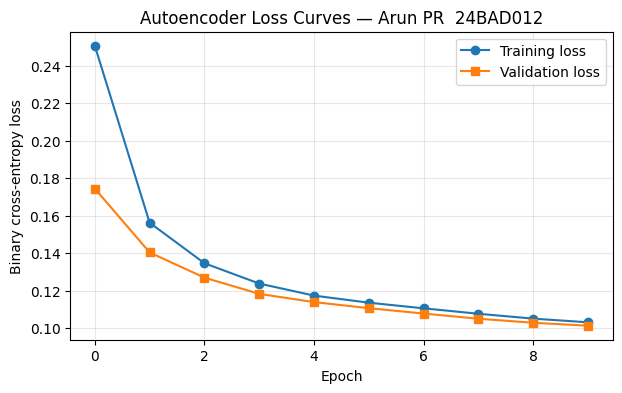

Final test BCE loss: 0.1014 | Test MSE: 0.01299


In [7]:
# Plot training and validation loss  |  Arun PR  24BAD012
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Autoencoder Loss Curves — Arun PR  24BAD012")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

test_loss, test_mse = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print(f"Final test BCE loss: {test_loss:.4f} | Test MSE: {test_mse:.5f}")

## Part D: Dimensionality Reduction, Feature Learning and Reconstruction

In [8]:
# Encode test images into latent vectors  |  Arun PR  24BAD012
latent_vectors = encoder.predict(x_test_flat, verbose=0)

print("Original input dimension :", x_test_flat.shape[1])
print("Latent dimension         :", latent_vectors.shape[1])
print("Compression ratio        : {:.1f}x".format(x_test_flat.shape[1] / latent_vectors.shape[1]))
print("Latent array shape       :", latent_vectors.shape)

# Decode latent vectors to reconstruct images
reconstructed = decoder.predict(latent_vectors, verbose=0)
print("Reconstructed shape      :", reconstructed.shape)

Original input dimension : 784
Latent dimension         : 32
Compression ratio        : 24.5x
Latent array shape       : (10000, 32)
Reconstructed shape      : (10000, 784)


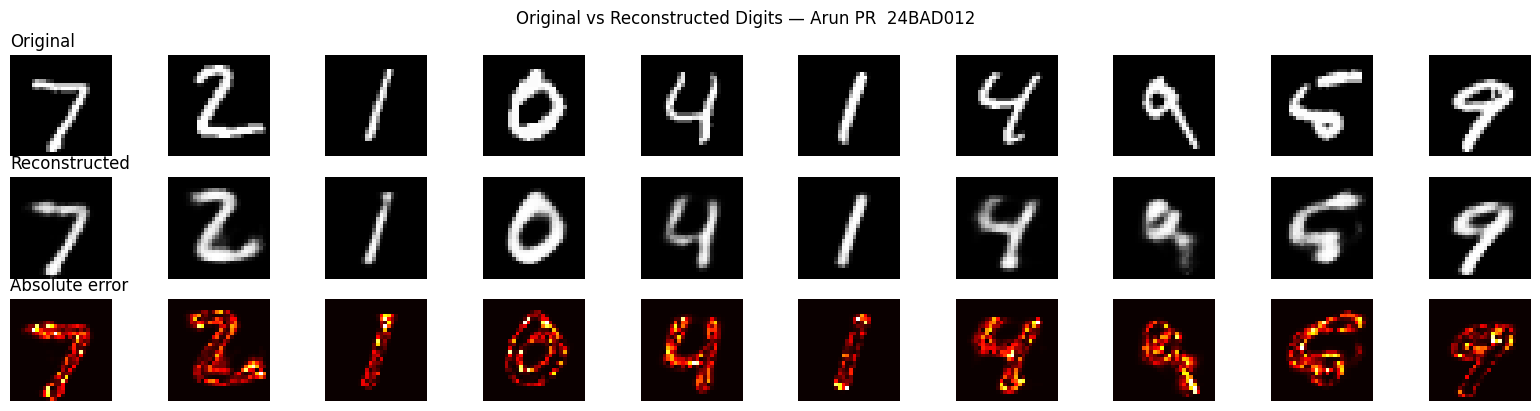

Mean reconstruction MSE over test set: 0.01299


In [9]:
# Original vs reconstructed  |  Arun PR  24BAD012
n = 10
plt.figure(figsize=(20, 4.5))
for i in range(n):
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test_flat[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    if i == 0: ax.set_title("Original", loc="left")

    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    if i == 0: ax.set_title("Reconstructed", loc="left")

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(np.abs(x_test_flat[i] - reconstructed[i]).reshape(28, 28), cmap="hot")
    ax.axis("off")
    if i == 0: ax.set_title("Absolute error", loc="left")
plt.suptitle("Original vs Reconstructed Digits — Arun PR  24BAD012")
plt.show()

per_image_mse = np.mean((x_test_flat - reconstructed) ** 2, axis=1)
print(f"Mean reconstruction MSE over test set: {per_image_mse.mean():.5f}")

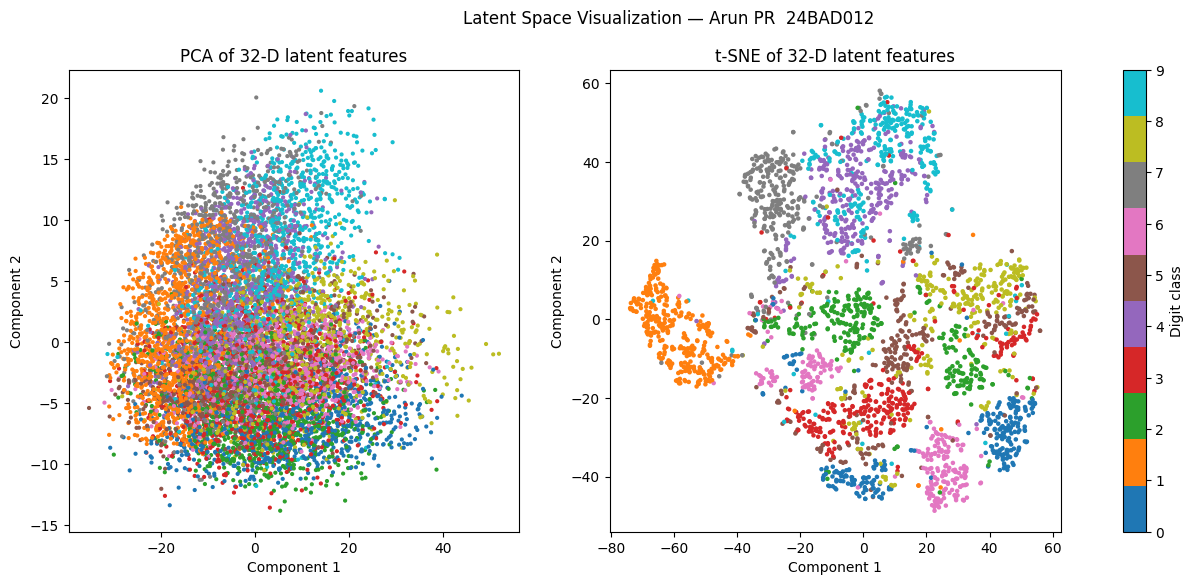

In [10]:
# Optional: visualize latent features in 2-D using PCA and t-SNE  |  Arun PR  24BAD012
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PCA on the full test latent set
pca_2d = PCA(n_components=2).fit_transform(latent_vectors)

# t-SNE on a subset (faster)
subset = 3000
tsne_2d = TSNE(n_components=2, random_state=31, init="pca", perplexity=30).fit_transform(latent_vectors[:subset])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc1 = axes[0].scatter(pca_2d[:, 0], pca_2d[:, 1], c=y_test, cmap="tab10", s=4)
axes[0].set_title("PCA of 32-D latent features")
sc2 = axes[1].scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=y_test[:subset], cmap="tab10", s=5)
axes[1].set_title("t-SNE of 32-D latent features")
for ax in axes:
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
fig.colorbar(sc2, ax=axes, ticks=range(10), label="Digit class")
fig.suptitle("Latent Space Visualization — Arun PR  24BAD012")
plt.show()

In [11]:
# Save trained models and reconstructed images  |  Arun PR  24BAD012
encoder.save("encoder_model.keras")
decoder.save("decoder_model.keras")
autoencoder.save("autoencoder_model.keras")
np.save("reconstructed_test_images.npy", reconstructed)
print("Saved: encoder_model.keras, decoder_model.keras, autoencoder_model.keras, reconstructed_test_images.npy")

Saved: encoder_model.keras, decoder_model.keras, autoencoder_model.keras, reconstructed_test_images.npy
